# 03 Features

Hand-crafted features for the logistic regression baseline:

0. Split each domain into subdomain / name / suffix (tldextract)
1. Basic character features and n-gram features
2. Markov chain score
3. Vowel features
4. TLD features

## Step 0: Split domains with tldextract

We split each domain into **subdomain**, **name** and **suffix** using `tldextract`
(not a simple split at the last dot, which gets `bbc.co.uk` wrong). We use the suffix
list bundled with tldextract 5.4.0, plus its private-suffix section (dynamic-DNS
services such as `ddns.net`) and 7 extra endings used by DGA families, so everyone
gets the same split.

All character features are computed on **text** = subdomain + name without dots,
and the TLD features on **suffix**, so the with/without-TLD experiments stay clean.

First, a quick check on a few example domains, including tricky ones.

In [12]:
# Let the notebook import our code from src/ (the project root is one folder up)
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.features.split import split_domain

# Expected: bbc.co.uk -> name 'bbc', suffix 'co.uk'
for d in ["google.com", "mail.google.com", "bbc.co.uk", "kneemanualgirl.com", "abc.ddns.net"]:
    print(d, "->", split_domain(d))

google.com -> ('', 'google', 'com')
mail.google.com -> ('mail', 'google', 'com')
bbc.co.uk -> ('', 'bbc', 'co.uk')
kneemanualgirl.com -> ('', 'kneemanualgirl', 'com')
abc.ddns.net -> ('', 'abc', 'ddns.net')


### Split the full dataset

We load the same 80/10/10 train/validation/test split as the baseline
(`load_splits()` from `src/data/dataset.py`) and add the **subdomain**, **name**,
**suffix** and **text** columns to each part.

In [13]:
from src.data.dataset import load_splits
from src.features.split import add_split_columns

# Same split as the baseline notebook, so all models see the same rows
train, val, test = load_splits()

# Add subdomain / name / suffix / text to each part (takes about a minute)
train = add_split_columns(train)
val = add_split_columns(val)
test = add_split_columns(test)

print(f"train: {len(train):,}  val: {len(val):,}  test: {len(test):,}")
print(train[["domain", "label", "family", "subdomain", "name", "suffix", "text"]].head(10))

# Sanity checks on all rows
for part_name, part in [("train", train), ("val", val), ("test", test)]:
    print(part_name,
          "| empty names:", (part["name"] == "").sum(),
          "| empty suffixes:", (part["suffix"] == "").sum())

train: 1,599,486  val: 199,936  test: 199,913
                           domain  label     family subdomain  \
0  6j29qz11hsefgh7oqsr1vpapri.com    dga   gameover             
1     qckuygxeyemxgongvylveeoh.cx    dga     necurs             
2                   arenaplus.net  legit      legit             
3                  fd5q27kyqb.com  legit      legit             
4              eksisozluk1923.com  legit      legit             
5                      ucngfq.com    dga      virut             
6                 mincetur.gob.pe  legit      legit             
7                      363ce3.net    dga  tinyfluff             
8                  w5pti45uow.net    dga    urlzone             
9                         acmb.cd    dga    qsnatch             

                         name  suffix                        text  
0  6j29qz11hsefgh7oqsr1vpapri     com  6j29qz11hsefgh7oqsr1vpapri  
1    qckuygxeyemxgongvylveeoh      cx    qckuygxeyemxgongvylveeoh  
2                   arenaplus     

### Check: every domain has a name and a suffix

A domain with an empty name or suffix means tldextract could not split it, which
would distort every feature. The cell below counts these rows, shows that the
previously problematic domains are now split correctly, and stops with an error if
any remain.

In [14]:
# 1) Count empty names / suffixes in every part (should all be 0 after the fix)
for part_name, part in [("train", train), ("val", val), ("test", test)]:
    print(part_name,
          "| empty names:", (part["name"] == "").sum(),
          "| empty suffixes:", (part["suffix"] == "").sum())

# 2) Show that the problem cases are now split correctly
examples = train[train["suffix"].isin(["bazar", "bazaar", "bit"]) | train["domain"].isin(["gov.bw", "ac.pk"])]
print(examples[["domain", "family", "subdomain", "name", "suffix"]].head(8))

# 3) Stop with an error if the problem ever comes back
for part_name, part in [("train", train), ("val", val), ("test", test)]:
    assert (part["name"] == "").sum() == 0, f"{part_name}: empty names"
    assert (part["suffix"] == "").sum() == 0, f"{part_name}: empty suffixes"
print("\nSplit check passed: no empty names or suffixes.")

train | empty names: 0 | empty suffixes: 0
val | empty names: 0 | empty suffixes: 0
test | empty names: 0 | empty suffixes: 0
                  domain         family subdomain          name  suffix
27        vuywibuf.bazar  bazarbackdoor                vuywibuf   bazar
59        aqewufuf.bazar  bazarbackdoor                aqewufuf   bazar
187       sonetoag.bazar  bazarbackdoor                sonetoag   bazar
223       ydidsoli.bazar  bazarbackdoor                ydidsoli   bazar
439       owywibty.bazar  bazarbackdoor                owywibty   bazar
487       omfeudag.bazar  bazarbackdoor                omfeudag   bazar
529       ucidizli.bazar  bazarbackdoor                ucidizli   bazar
636  eadhimecfhit.bazaar  bazarbackdoor            eadhimecfhit  bazaar

Split check passed: no empty names or suffixes.


**Finding.** At first, 23,743 train domains (all DGA) had an empty suffix: they use
endings from alternative DNS systems that tldextract does not know: `.bazar` /
`.bazaar` (bazarbackdoor), `.bit` (necurs), `.load` (gozi), `.oss` / `.geek` /
`.web` (other_dga). tldextract then put the ending in `name` (e.g. `edwiudli.bazar`
→ name `bazar`). Also 8 legit domains are themselves official suffixes (e.g.
`gov.bw`) and had an empty name.

**Fix.** These 7 endings are passed to tldextract (`EXTRA_SUFFIXES` in
`src/features/split.py`); for the 8 `gov.bw`-style domains, the first label of the
suffix becomes the name (to confirm with the team).

**Note.** These endings appear only in DGA domains, so the TLD alone identifies
these families: one reason we test every model with and without the TLD.

### Check: domains with a subdomain

Domains that still have a subdomain after the split, with their `text` column.

In [15]:
print(train[train["subdomain"] != ""][["domain", "subdomain", "name", "text"]].head(10))

                                                 domain  \
291              e9e10c8bb9cb2465686d0f825a25dadc.co.cc   
1255             3c52819a24e6df2c565c9e1cb5ff5233.cz.cc   
1550                                 ns1.backdates4.net   
1696                          www1.runprettyquarter.art   
1728  oeldhchgibwccxchdeebchdeecegqfucegqfa.brazilso...   
1903                      ffeearwedeglhpwh.mynumber.org   
2067                                       slbla.uy.com   
2163  m0d1854739a115ca987292a04214be75d955c3.brazils...   
2875                            cditpjxmgdy.dynserv.com   
3498             163b628e3ae5f90d3804ea83d96eaa1c.co.cc   

                                              subdomain              name  \
291                    e9e10c8bb9cb2465686d0f825a25dadc                co   
1255                   3c52819a24e6df2c565c9e1cb5ff5233                cz   
1550                                                ns1        backdates4   
1696                                      

**Dynamic DNS.** Many DGA domains are created under free services (`ddns.net`,
`duckdns.org`, ...). With `include_psl_private_domains=True`, tldextract treats these
as suffixes, so the random part becomes the name. Services missing from that list
(`co.cc`, `dynserv.com`, ...) still have their random part in `text`
(subdomain + name, no dots), which is what all character features use.

## Step 1: Basic character features and n-gram features

Two groups of features, both computed on `text` (subdomain + name, no dots), never on
the suffix:

- **1a. Basic character features:** length, digits, hyphens, how varied and random the
  characters are (`src/features/handcrafted.py`).
- **1b. N-gram features:** how common the domain's 2- and 3-letter groups are in
  legitimate domains (`src/features/ngrams.py`).

### 1a. Basic character features

Seven numbers per domain: `length`, `digit_ratio`, `hyphen_ratio`, `unique_char_ratio`,
`entropy` (how random the characters look, in bits), `longest_digit_run` and
`starts_with_digit`. These need no training, so they are computed the same way on
train, validation and test. The table shows the average of each feature for legit and
DGA domains in the training set.

In [16]:
import pandas as pd
from src.features.handcrafted import basic_features

basic_train = basic_features(train["text"])
basic_val = basic_features(val["text"])
basic_test = basic_features(test["text"])

# Average of each feature, legit vs DGA (training set)
print(basic_train.groupby(train["label"]).mean().T.round(3))

label                 dga  legit
length             14.255  9.635
digit_ratio         0.151  0.039
hyphen_ratio        0.003  0.010
unique_char_ratio   0.760  0.818
entropy             3.148  2.738
longest_digit_run   1.057  0.256
starts_with_digit   0.115  0.028


**1a result** (averages, DGA vs legit):

- DGA names are longer: 14.3 vs 9.6 characters.
- DGA names have slightly higher entropy (3.15 vs 2.74 bits), partly because they are longer.
- DGA names have about 4× more digits.
- Legit names use 3× more hyphens.
- `unique_char_ratio` is lower for DGA because longer names repeat letters.
- Averages hide overlap; see the ROC-AUC table below.

### 1b. N-gram features

An n-gram is a group of n characters in a row (`google` → 2-grams `^g go oo og gl le e$`,
where `^` and `$` mark the start and end). We count every 2-gram and 3-gram in the
**legitimate training domains**, then give each domain 4 scores per n:

- `ng{n}_mean`: average log-frequency of its n-grams (higher = more normal)
- `ng{n}_min`: log-frequency of its rarest n-gram
- `ng{n}_rare`: share of its n-grams that are rare in legit domains (less than 1 in a million)
- `ng{n}_top`: share of its n-grams among the 500 most common legit n-grams

(A first version used "never seen" instead of "rare", but it was almost always 0:
nearly every 2- and 3-gram appears somewhere among 800k legit names.)
For 2-grams even "rare" is always 0 (only about 1,400 possible 2-grams, all common),
so `ng2_rare` is dropped: 7 n-gram features, and 14 features in step 1.

**No leakage.** The counts come from the training set only. Inside the training set we
use 5 folds: a training row is scored with counts from the *other* folds. The second
table checks this: the `rare` averages should be similar in train and validation.

In [17]:
from src.features.ngrams import ngram_features

ng_train, ng_val, ng_test = ngram_features(train, val, test)

# ng2_rare is always 0: every 2-gram appears often in 800k legit names. Drop it.
ng_train, ng_val, ng_test = (d.drop(columns="ng2_rare") for d in (ng_train, ng_val, ng_test))

# Average of each feature, legit vs DGA (training set)
print(ng_train.groupby(train["label"]).mean().T.round(3), "\n")

# Leakage check: 'rare' should be similar in train and validation
check = pd.DataFrame({
    "train": ng_train.groupby(train["label"])["ng3_rare"].mean(),
    "val": ng_val.groupby(val["label"])["ng3_rare"].mean(),
})
print(check.round(4))

label       dga  legit
ng2_mean -3.351 -2.655
ng2_min  -4.349 -3.464
ng2_top   0.595  0.923
ng3_mean -5.041 -3.818
ng3_min  -6.071 -4.748
ng3_rare  0.196  0.016
ng3_top   0.057  0.346 

        train     val
label                
dga    0.1963  0.1830
legit  0.0164  0.0151


### How well does each feature separate legit from DGA?

For each feature on its own, we compute the ROC-AUC on the validation set:
**0.5** = useless (no better than chance), **1.0** = perfectly higher for DGA,
**0.0** = perfectly higher for legit. So the further from 0.5, the more useful.
We also check that no feature has missing values.

In [18]:
from sklearn.metrics import roc_auc_score

step1_val = pd.concat([basic_val, ng_val], axis=1)
y_val = (val["label"] == "dga").astype(int)

assert not step1_val.isna().any().any(), "missing values in step 1 features"

auc = step1_val.apply(lambda col: roc_auc_score(y_val, col))
strength = (auc - 0.5).abs()   # distance from 0.5 = how useful
print(pd.DataFrame({"roc_auc": auc, "strength": strength})
        .sort_values("strength", ascending=False).round(3))

                   roc_auc  strength
ng3_mean             0.078     0.422
ng3_min              0.087     0.413
ng2_mean             0.097     0.403
ng2_top              0.120     0.380
ng2_min              0.121     0.379
ng3_top              0.134     0.366
ng3_rare             0.806     0.306
length               0.723     0.223
entropy              0.711     0.211
digit_ratio          0.620     0.120
longest_digit_run    0.618     0.118
unique_char_ratio    0.392     0.108
starts_with_digit    0.544     0.044
hyphen_ratio         0.468     0.032


**Feature strength** (effective AUC, alone, validation set):

- AUC below 0.5 means higher values point to legit, so 0.08 works like 0.92.
- N-gram features are the strongest: 0.87–0.92 (best: `ng3_mean`).
- `ng3_rare` (share of rare 3-grams) is also strong: 0.81.
- `length` and `entropy` are medium: about 0.72.
- Digit features and `unique_char_ratio` are weak: about 0.62.
- `starts_with_digit` and `hyphen_ratio` are near 0.5 (almost useless alone).
- These are single features; weak ones may still help in combination.

### Distributions of four features (validation set)

Histograms of four features for legit and DGA domains. The more the two colours
overlap, the harder that feature alone makes it to tell them apart.

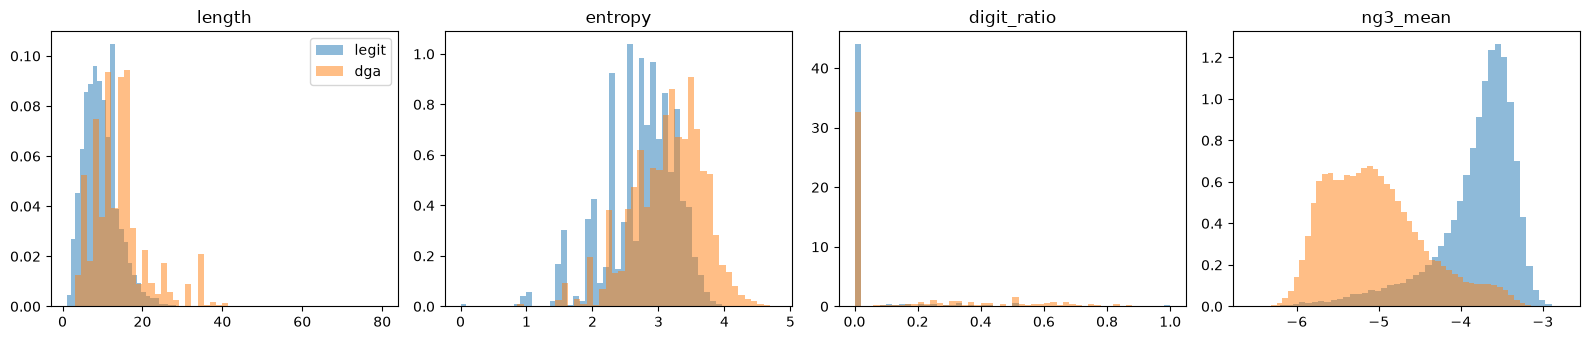

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["length", "entropy", "digit_ratio", "ng3_mean"]):
    for label in ["legit", "dga"]:
        ax.hist(step1_val.loc[val["label"] == label, col], bins=50,
                alpha=0.5, density=True, label=label)
    ax.set_title(col)
axes[0].legend()
plt.tight_layout()
plt.show()

**Step 1 result.** 14 features: 7 basic + 7 n-gram.

- `ng3_mean` separates best: two clear humps (DGA ≈ −5.5, legit ≈ −3.5).
- `length` and `entropy` overlap a lot; they help only a little alone.
- `digit_ratio` is 0 for most domains of both classes; it only flags hex/digit DGA families.
- A small group of DGA domains has normal-looking n-grams (right of `ng3_mean`):
  likely dictionary DGAs, the hardest case.
- "Never seen" n-grams were useless (almost every n-gram appears in legit names);
  replaced by "rare" n-grams. `ng2_rare` is always 0 and was dropped.

## Step 2: Markov chain score

A Markov chain answers: *given the previous letter(s), how likely is the next one?*
We learn these probabilities from the **legitimate training names**, then score each
domain by how expected each of its letters was (`src/features/markov.py`).

- `markov1`: looks at the previous 1 character (after `q`, `u` is very likely)
- `markov2`: looks at the previous 2 characters (after `th`, `e` is very likely)

Each score is the **average log10 probability per letter**: closer to 0 = flows like a
real name, more negative = looks random. Example: `google` scores high, `xkqjzp` low.

Same rules as the n-gram features: computed on `text`, counts from the legit training
rows only, and training rows scored with counts from the other 4 folds (same folds).
The second table is the leakage check (train and validation should be similar).



In [20]:
from src.features.markov import markov_features

mk_train, mk_val, mk_test = markov_features(train, val, test)

# Average score, legit vs DGA (training set)
print(mk_train.groupby(train["label"]).mean().T.round(3), "\n")

# Leakage check: train and validation averages should be similar
check = pd.DataFrame({
    "train": mk_train.groupby(train["label"]).mean().stack(),
    "val": mk_val.groupby(val["label"]).mean().stack(),
})
print(check.round(3))

label      dga  legit
markov1 -1.692 -1.271
markov2 -1.690 -1.194 

               train    val
label                      
dga   markov1 -1.692 -1.692
      markov2 -1.690 -1.691
legit markov1 -1.271 -1.271
      markov2 -1.194 -1.194


### How useful is the Markov score?

ROC-AUC of each Markov score on the validation set (as in step 1: far from 0.5 = useful,
below 0.5 = higher values point to legit). We also check how strongly it is correlated
with `ng3_mean`, the best step 1 feature: a correlation close to 1 means the Markov
score mostly repeats what the n-gram features already know.

In [21]:
assert not mk_val.isna().any().any(), "missing values in Markov features"

auc = mk_val.apply(lambda col: roc_auc_score(y_val, col))
print(pd.DataFrame({"roc_auc": auc, "strength": (auc - 0.5).abs()}).round(3), "\n")

# Correlation with the best step 1 feature (1 = same information, 0 = unrelated)
print("correlation with ng3_mean:")
print(mk_val.corrwith(ng_val["ng3_mean"]).round(3))

         roc_auc  strength
markov1    0.082     0.418
markov2    0.064     0.436 

correlation with ng3_mean:
markov1    0.975
markov2    0.951
dtype: float64


### Distribution of the Markov scores (validation set)

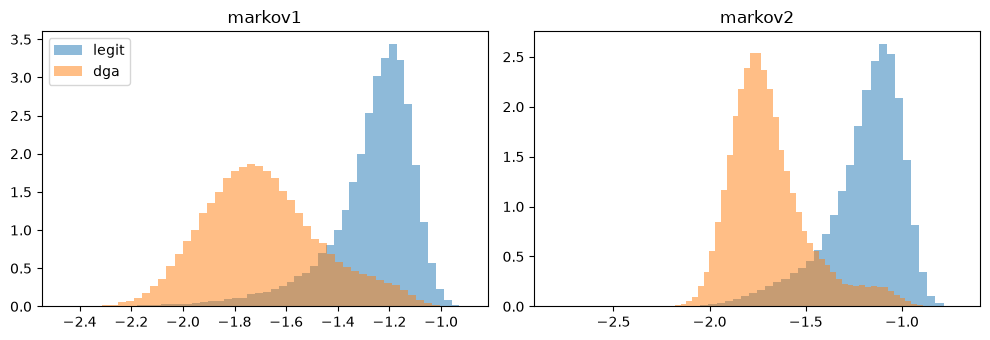

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["markov1", "markov2"]):
    for label in ["legit", "dga"]:
        ax.hist(mk_val.loc[val["label"] == label, col], bins=50,
                alpha=0.5, density=True, label=label)
    ax.set_title(col)
axes[0].legend()
plt.tight_layout()
plt.show()

**Step 2 result.** *(fill in after running)*

- Histograms: `markov2` gives two clearly separated humps; a tail of DGA domains scores
  like legit names (likely dictionary DGAs, as with `ng3_mean`).